In [1]:
import polars as pl
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Ajuste o caminho conforme a localização real no seu ambiente

# Localiza a raiz do projeto a partir do diretório atual do notebook.
# Assim o notebook funciona no VS Code, Jupyter local ou outro clone do repositório.
def encontrar_raiz_projeto():
    atual = Path.cwd().resolve()
    for candidato in [atual, *atual.parents]:
        if (candidato / "dados" / "principal" / "ml_aluno.zip").exists():
            return candidato
    raise FileNotFoundError(
        "Não foi possível encontrar dados/principal/ml_aluno.zip. "
        "Execute o notebook dentro do repositório ou confira se os dados foram baixados."
    )

PROJECT_ROOT = encontrar_raiz_projeto()

BASE_PATH = PROJECT_ROOT / "dados" / "consolidado" / "base_alunos_municipios_por_uf"
# Leitura lazy (muito mais eficiente com partições)
df = pl.scan_parquet(
    f"{BASE_PATH}/sigla_uf=*/00000000.parquet",
    hive_partitioning=True
)

In [3]:
# Análise completa de missing values
missing_analysis = (
    df
    .select([
        pl.len().alias("total_registros"),
        *[pl.col(col).null_count().alias(col) for col in df.collect_schema().names()]
    ])
    .collect()
    .unpivot(index="total_registros", on=df.collect_schema().names(), variable_name="coluna", value_name="nulos")
    .with_columns(
        (pl.col("nulos") / pl.col("total_registros") * 100).round(2).alias("pct_nulos")
    )
    .filter(pl.col("coluna") != "total_registros")  # remove a coluna auxiliar se aparecer
    .sort("pct_nulos", descending=True)
)

print("=== Ranking de Missing Values ===")
print(missing_analysis)

# Resumo rápido
print("\n=== Resumo ===")
print(f"Total de colunas analisadas: {missing_analysis.height}")
print(f"Colunas com missing values: {missing_analysis.filter(pl.col('nulos') > 0).height}")
print(f"Colunas 100% preenchidas: {missing_analysis.filter(pl.col('nulos') == 0).height}")

=== Ranking de Missing Values ===
shape: (49, 4)
┌─────────────────┬───────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                   ┆ ---     ┆ ---       │
│ u64             ┆ str                   ┆ u64     ┆ f64       │
╞═════════════════╪═══════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ qtd_escolas_inse      ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ qtd_alunos_inse       ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ media_inse            ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ pc_nivel_1            ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ pc_nivel_2            ┆ 2121761 ┆ 54.85     │
│ …               ┆ …                     ┆ …       ┆ …         │
│ 3867999         ┆ preenchimento_caderno ┆ 0       ┆ 0.0       │
│ 3867999         ┆ dataset_split         ┆ 0       ┆ 0.0       │
│ 3867999         ┆ alfabetizado          ┆ 0       ┆ 0.0       │
│ 3867999         ┆ process

In [4]:
# Mostra todas as colunas com missing > 0
print(missing_analysis.filter(pl.col("pct_nulos") > 0))

shape: (33, 4)
┌─────────────────┬─────────────────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                          ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                             ┆ ---     ┆ ---       │
│ u64             ┆ str                             ┆ u64     ┆ f64       │
╞═════════════════╪═════════════════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ qtd_escolas_inse                ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ qtd_alunos_inse                 ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ media_inse                      ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ pc_nivel_1                      ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ pc_nivel_2                      ┆ 2121761 ┆ 54.85     │
│ …               ┆ …                               ┆ …       ┆ …         │
│ 3867999         ┆ media_portugues_municipio_ano_… ┆ 1791646 ┆ 46.32     │
│ 3867999         ┆ proficiencia                    ┆ 513338  ┆ 13.27    

In [5]:
#Ranking completo formatado
with pl.Config(tbl_rows=50, fmt_str_lengths=50):
    print(missing_analysis)

shape: (49, 4)
┌─────────────────┬───────────────────────────────────────────┬─────────┬───────────┐
│ total_registros ┆ coluna                                    ┆ nulos   ┆ pct_nulos │
│ ---             ┆ ---                                       ┆ ---     ┆ ---       │
│ u64             ┆ str                                       ┆ u64     ┆ f64       │
╞═════════════════╪═══════════════════════════════════════════╪═════════╪═══════════╡
│ 3867999         ┆ qtd_escolas_inse                          ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ qtd_alunos_inse                           ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ media_inse                                ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ pc_nivel_1                                ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ pc_nivel_2                                ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ pc_nivel_3                                ┆ 2121761 ┆ 54.85     │
│ 3867999         ┆ pc_nivel_4         

In [6]:
# 
print(
    missing_analysis
    .select("coluna", "pct_nulos")
    .filter(pl.col("pct_nulos") > 0)
    .sort("pct_nulos", descending=True)
)

shape: (33, 2)
┌─────────────────────────────────┬───────────┐
│ coluna                          ┆ pct_nulos │
│ ---                             ┆ ---       │
│ str                             ┆ f64       │
╞═════════════════════════════════╪═══════════╡
│ qtd_escolas_inse                ┆ 54.85     │
│ qtd_alunos_inse                 ┆ 54.85     │
│ media_inse                      ┆ 54.85     │
│ pc_nivel_1                      ┆ 54.85     │
│ pc_nivel_2                      ┆ 54.85     │
│ …                               ┆ …         │
│ media_portugues_municipio_ano_… ┆ 46.32     │
│ proficiencia                    ┆ 13.27     │
│ peso_aluno                      ┆ 13.27     │
│ valor_receitas                  ┆ 0.89      │
│ valor_fundeb                    ┆ 0.87      │
└─────────────────────────────────┴───────────┘


### Estratégia de tratamento recomendada

1. Grupo Crítico (> 50%) – Variáveis INSE + PIB + Censo
   - Opção A (mais conservadora): Remover essas colunas (perda de informação, mas evita viés forte de missing).
   - Opção B (recomendada se forem importantes): 
        - Criar uma flag `tem_inse = 1 se media_inse não nulo`
        - Imputar com mediana (ou mediana por UF)
        - Ou usar modelos que lidam nativamente com missing (LightGBM, XGBoost, CatBoost)

2. Grupo Alto (40-50%)
   - `media_portugues_municipio...`: mesma lógica do INSE (flag + imputação ou remoção).

3. Grupo Moderado (10-20%)
   - `proficiencia` e `peso_aluno`:
        - Criar flag de missing
        - Imputar com mediana (ou mediana por UF / dependência administrativa)

4. Grupo Baixo (< 1%)
   - `valor_receitas` e `valor_fundeb`: imputar com mediana ou 0 (dependendo do significado de negócio).

In [7]:
# Força mostrar todas as 33 linhas
missing_full = (
    missing_analysis
    .select("coluna", "pct_nulos")
    .filter(pl.col("pct_nulos") > 0)
    .sort("pct_nulos", descending=True)
)

# Imprime como lista de tuplas (não trunca)
print(list(zip(missing_full["coluna"].to_list(), missing_full["pct_nulos"].to_list())))

[('qtd_escolas_inse', 54.85), ('qtd_alunos_inse', 54.85), ('media_inse', 54.85), ('pc_nivel_1', 54.85), ('pc_nivel_2', 54.85), ('pc_nivel_3', 54.85), ('pc_nivel_4', 54.85), ('pc_nivel_5', 54.85), ('pc_nivel_6', 54.85), ('pc_nivel_7', 54.85), ('pc_nivel_8', 54.85), ('nome uf', 54.82), ('nome do município', 54.82), ('valor_pib', 54.82), ('valor_pib_per_capita', 54.82), ('qtd_escolas_censo', 54.82), ('qt_mat_bas', 54.82), ('qt_doc_bas', 54.82), ('qt_tur_bas', 54.82), ('in_biblioteca_sala_leitura', 54.82), ('in_laboratorio_informatica', 54.82), ('in_quadra_esportes', 54.82), ('in_agua_rede_publica', 54.82), ('in_energia_rede_publica', 54.82), ('in_esgoto_rede_publica', 54.82), ('in_internet', 54.82), ('in_banda_larga', 54.82), ('taxa_alfabetizacao_municipio_ano_anterior', 46.32), ('media_portugues_municipio_ano_anterior', 46.32), ('proficiencia', 13.27), ('peso_aluno', 13.27), ('valor_receitas', 0.89), ('valor_fundeb', 0.87)]


### Classificação Final por Gravidade

| Grupo | % Missing | Colunas | Qtd | Recomendação principal |
|---|---:|---|---:|---|
| **Crítico** | 54,85% | `qtd_escolas_inse`, `qtd_alunos_inse`, `media_inse`, `pc_nivel_1` a `pc_nivel_8` | 11 | Avaliar importância. Se forem preditivas, criar flag + imputar. Caso contrário, remover. |
| **Crítico** | 54,82% | `nome_uf`, `nome_do_município`, `valor_pib`, `valor_pib_per_capita`, `qtd_escolas_censo`, `qt_mat_bas`, `qt_doc_bas`, `qt_tur_bas`, `in_biblioteca_sala_leitura`, `in_laboratorio_informatica`, `in_quadra_esportes`, `in_agua_rede_publica`, `in_energia_rede_publica`, `in_esgoto_rede_publica`, `in_internet`, `in_banda_larga` | 16 | Mesmo padrão de missing (join falhou). A maioria são variáveis de infraestrutura escolar e PIB. |
| **Alto** | 46,32% | `taxa_alfabetizacao_municipio_ano_anterior`, `media_portugues_municipio_ano_anterior` | 2 | Features agregadas municipais. Criar flag + imputar ou remover. |
| **Moderado** | 13,27% | `proficiencia`, `peso_aluno` | 2 | Imputar + criar flag de missing. |
| **Baixo** | < 1% | `valor_receitas` (0,89%), `valor_fundeb` (0,87%) | 2 | Imputação simples (mediana ou 0). |



### Observações importantes

1. **Dois grandes blocos com missing idêntico (54,8%)**
   - Bloco INSE (11 colunas).
   - Bloco Censo Escolar + PIB + infraestrutura (16 colunas).

   Isso indica que o mesmo conjunto de municípios/escolas pode não ter correspondência (*match*) nas bases externas.

2. **Features agregadas municipais**

   `taxa_alfabetizacao_municipio_ano_anterior` e `media_portugues_municipio_ano_anterior` também apresentam alto percentual de missing, possivelmente correlacionado.

3. **Features de desempenho e peso amostral**

   `proficiencia` e `peso_aluno` compartilham exatamente o mesmo percentual de missing, de **13,27%**, indicando um possível padrão comum de ausência.


### Estratégia de tratamento de missing por grupo

#### Grupo 1 – Crítico (54,8%) → 27 colunas

- **Opção A (mais simples e segura):** remover todas as colunas.
- **Opção B (se quiser manter a informação):**
  - Criar uma flag por bloco: `tem_inse` e `tem_censo_infra`.
  - Imputar os valores ausentes com a mediana global ou a mediana por UF.

#### Grupo 2 – Alto (46,3%) → 2 colunas

- Criar a flag `tem_indicadores_municipais`.
- Imputar os valores ausentes com a mediana por UF.

#### Grupo 3 – Moderado (13,3%) → 2 colunas

- Criar a flag `tem_proficiencia`.
- Imputar `proficiencia` e `peso_aluno` com a mediana global ou a mediana por UF.

#### Grupo 4 – Baixo (< 1%) → 2 colunas

- Imputar os valores ausentes com a mediana ou com `0`, dependendo do significado da variável.



## Diagnóstico principal


O problema não é de formatação de chave (id_municipio parece estar correto como int64).

O problema é de cobertura temporal (ano).


| Base externa              | Anos disponíveis | Anos na base de alunos | Consequência                            |
|---------------------------|------------------|------------------------|-----------------------------------------|
| **INSE**                  | **Somente 2023** | 2023 + **2024**        | Todos os alunos de 2024 ficam sem INSE  |
| **Censo Escolar**         | **Somente 2023** | 2023 + **2024**        | Todos os alunos de 2024 ficam sem Censo |
| **PIB**                   | 2022 + 2023      | 2023 + **2024**        | Alunos de 2024 ficam sem PIB            |
| Bolsa / Fundeb / Receitas | 2023 + 2024      | 2023 + 2024            | Quase completo (por isso, missing < 1%) |



Por isso o missing de ~54,8% aparece exatamente no mesmo percentual em dezenas de colunas (INSE + Censo + PIB).

Esse percentual corresponde aproximadamente à proporção de alunos do ano 2024.






### Como corrigir (opções)

#### Opções para tratar os dados ausentes

**Opção 1 — Usar os dados do ano anterior (recomendado)**

Usar os dados do **ano anterior** quando não houver informações disponíveis para o ano corrente:

- Para alunos de **2024** → usar INSE 2023, Censo Escolar 2023 e PIB 2023.
- Para alunos de **2023** → usar os dados de 2023.

Essa é uma prática comum na construção de *features* socioeconômicas, pois o contexto do município tende a mudar gradualmente de um ano para outro.

**Opção 2 — Remover os alunos de 2024 da análise**

Excluir os registros de 2024, reduzindo o volume de dados disponível para o treinamento e a avaliação do modelo.

**Opção 3 — Buscar as bases de 2024 do INSE e do Censo Escolar**

Verificar se as bases referentes a 2024 já foram publicadas e, caso estejam disponíveis, incorporá-las à análise para reduzir o percentual de valores ausentes.




=== Features Numéricas identificadas ===
['id_municipio', 'ano_referencia', 'serie', 'rede', 'presenca', 'preenchimento_caderno', 'proficiencia', 'peso_aluno', 'taxa_alfabetizacao_municipio_ano_anterior', 'media_portugues_municipio_ano_anterior', 'valor_bolsa_familia', 'valor_fundeb', 'valor_receitas', 'valor_pib', 'valor_pib_per_capita', 'qtd_escolas_inse', 'qtd_alunos_inse', 'media_inse', 'pc_nivel_1', 'pc_nivel_2', 'pc_nivel_3', 'pc_nivel_4', 'pc_nivel_5', 'pc_nivel_6', 'pc_nivel_7', 'pc_nivel_8', 'qtd_escolas_censo', 'qt_mat_bas', 'qt_doc_bas', 'qt_tur_bas', 'in_biblioteca_sala_leitura', 'in_laboratorio_informatica', 'in_quadra_esportes', 'in_agua_rede_publica', 'in_energia_rede_publica', 'in_esgoto_rede_publica', 'in_internet', 'in_banda_larga']

Total: 38

=== Features Categóricas identificadas ===
['nome_municipio', 'sigla_uf', 'rede_descricao', 'caderno', 'dataset_split', 'alfabetizado', 'nome uf', 'nome do município']

Total: 8

DISTRIBUIÇÃO DAS FEATURES NUMÉRICAS
shape: (9, 3

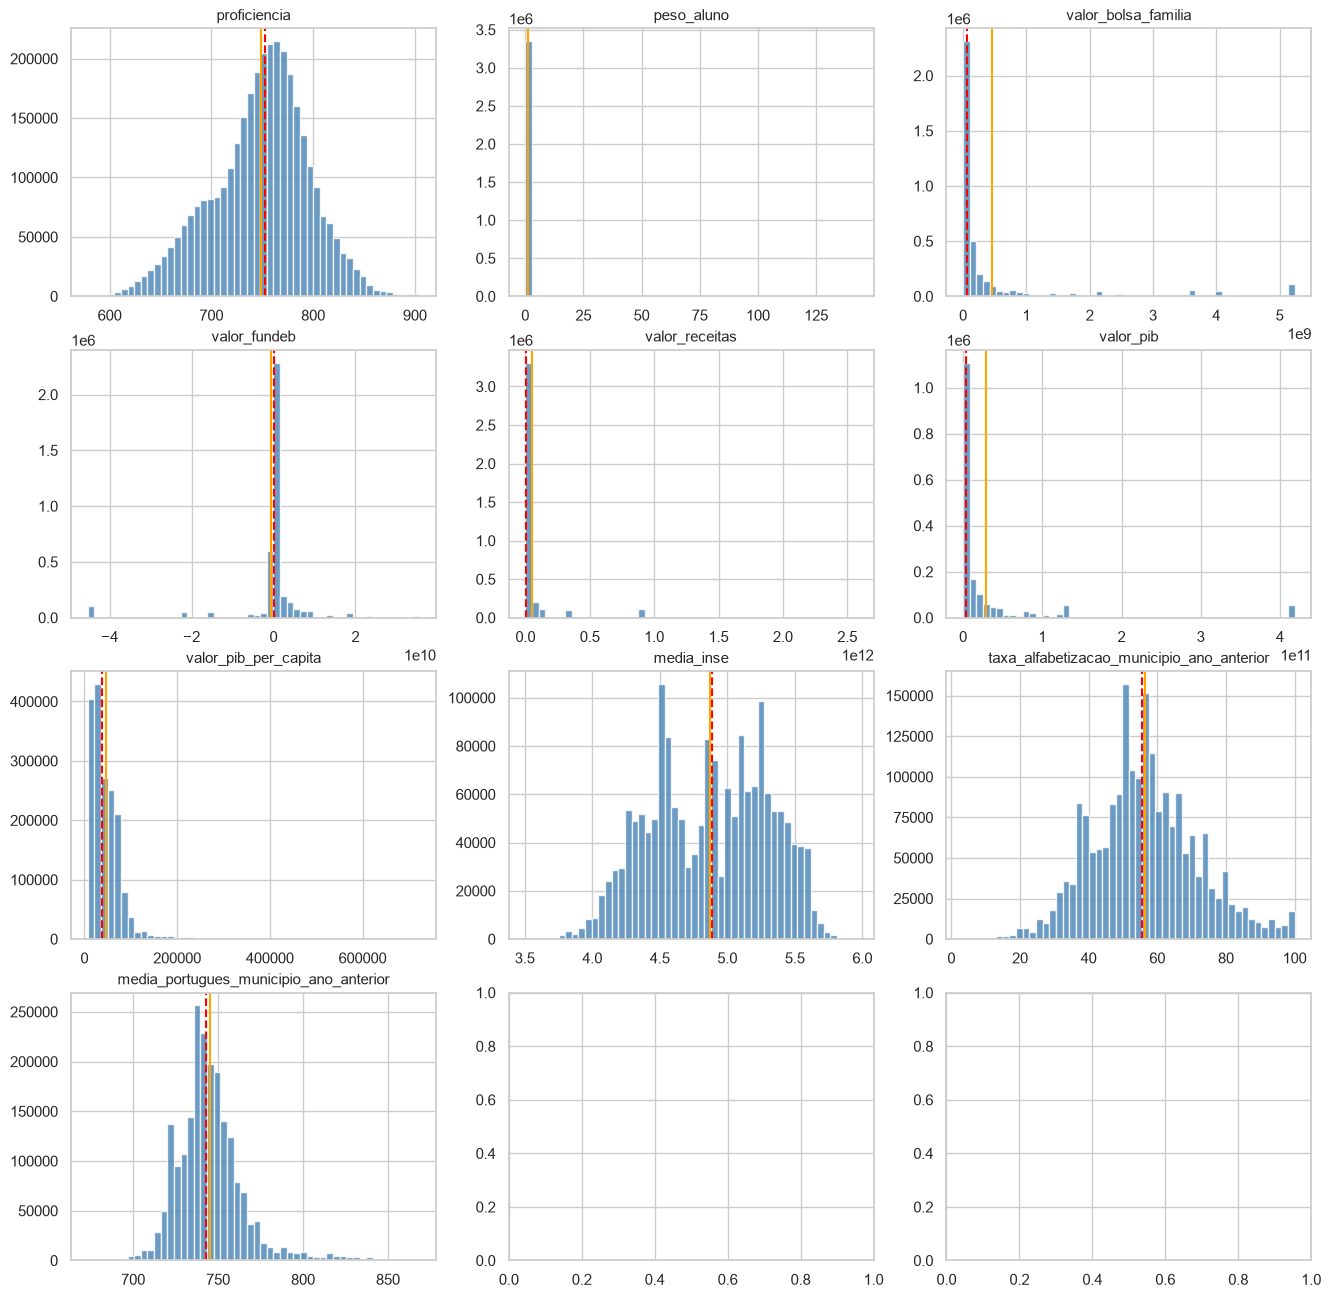

In [8]:
# ============================================================
# Análise de Distribuição das Principais Features
# Numéricas e Categóricas
# ============================================================

import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)

# ------------------------------------------------------------
# 1. Separar features numéricas e categóricas
# ------------------------------------------------------------
schema = df.collect_schema() if hasattr(df, "collect_schema") else df.schema

# Ajuste conforme o nome real do seu LazyFrame/DataFrame
# Se estiver usando o consolidado:
# df_analise = pl.scan_parquet("consolidado_base_alunos_municipios_por_uf/sigla_uf=*/00000000.parquet", hive_partitioning=True)
# ou se já tiver o DataFrame em memória:
df_analise = df  # troque pelo nome real se necessário

# Coleta apenas o necessário para não estourar memória
df_sample = df_analise.collect() if hasattr(df_analise, "collect") else df_analise

colunas_numericas = [
    col for col, dtype in df_sample.schema.items()
    if dtype in (pl.Float32, pl.Float64, pl.Int8, pl.Int16, pl.Int32, pl.Int64, pl.UInt8, pl.UInt16, pl.UInt32, pl.UInt64)
    and col not in ["alfabetizado"]  # target já analisado
]

colunas_categoricas = [
    col for col, dtype in df_sample.schema.items()
    if dtype in (pl.Utf8, pl.Categorical, pl.Boolean, pl.Int8, pl.Int16, pl.Int32, pl.Int64)
    and col not in colunas_numericas
    and col not in ["id_aluno", "id_escola", "id_municipio", "processed_at"]  # IDs e timestamps
]

print("=== Features Numéricas identificadas ===")
print(colunas_numericas)
print(f"\nTotal: {len(colunas_numericas)}")

print("\n=== Features Categóricas identificadas ===")
print(colunas_categoricas)
print(f"\nTotal: {len(colunas_categoricas)}")

# ------------------------------------------------------------
# 2. Análise descritiva das features NUMÉRICAS
# ------------------------------------------------------------
print("\n" + "="*70)
print("DISTRIBUIÇÃO DAS FEATURES NUMÉRICAS")
print("="*70)

desc_numericas = (
    df_sample
    .select(colunas_numericas)
    .describe()
)

print(desc_numericas)

# Estatísticas extras: assimetria (skewness) e curtose
print("\n--- Assimetria (Skewness) e Curtose ---")
stats_extras = []
for col in colunas_numericas:
    serie = df_sample[col].drop_nulls()
    if serie.len() > 0:
        skew = serie.skew()
        # Curtose não tem método nativo direto em versões antigas do Polars,
        # então calculamos via pandas se necessário
        try:
            kurt = serie.to_pandas().kurtosis()
        except:
            kurt = None
        stats_extras.append({
            "coluna": col,
            "skewness": round(skew, 3) if skew is not None else None,
            "kurtosis": round(kurt, 3) if kurt is not None else None,
            "nulos_pct": round(df_sample[col].null_count() / df_sample.height * 100, 2)
        })

df_stats_extras = pl.DataFrame(stats_extras).sort("skewness", descending=True)
print(df_stats_extras)

# Interpretação rápida da assimetria
print("\n--- Interpretação da Assimetria ---")
print("""
Skewness ≈ 0          → distribuição aproximadamente simétrica
Skewness > 1          → assimetria positiva forte (cauda à direita)
Skewness < -1         → assimetria negativa forte (cauda à esquerda)
|Skewness| entre 0.5 e 1 → assimetria moderada
""")

# ------------------------------------------------------------
# 3. Visualizações das principais features numéricas
# ------------------------------------------------------------
# Seleciona as mais relevantes (ajuste a lista conforme sua prioridade)
features_plot = [
    c for c in [
        "proficiencia", "peso_aluno", "valor_bolsa_familia",
        "valor_fundeb", "valor_receitas", "valor_pib",
        "valor_pib_per_capita", "media_inse",
        "taxa_alfabetizacao_municipio_ano_anterior",
        "media_portugues_municipio_ano_anterior"
    ] if c in colunas_numericas
]

n_feats = len(features_plot)
n_cols = 3
n_rows = (n_feats + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))
axes = axes.flatten() if n_feats > 1 else [axes]

for i, col in enumerate(features_plot):
    data = df_sample[col].drop_nulls().to_numpy()
    axes[i].hist(data, bins=50, color="steelblue", edgecolor="white", alpha=0.8)
    axes[i].axvline(np.median(data), color="red", linestyle="--", label=f"Mediana: {np.median(data):.2f}")
    axes[i].axvline(np.mean(data), color="orange", linestyle="-", label=f"Média: {np.mean(data):.2f}")
    axes[i].set_title(col, fontsize=11)

# Análise dos resultados – Distribuição das Features

## 1. Features Numéricas – Principais achados

| Feature | Comportamento observado | Interpretação | Recomendação |
|---|---|---|---|
| **proficiencia** | Quase simétrica, centrada em aproximadamente 740–750 | Boa distribuição, próxima da normal | Manter como está |
| **peso_aluno** | Forte concentração perto de 0 + cauda longa | Assimetria positiva extrema | Considerar log ou winsorização |
| **valor_bolsa_familia** | Fortemente assimétrica, com muitos valores baixos | Cauda longa à direita | `log1p` recomendado |
| **valor_fundeb** | Concentração em torno de 0 + outliers negativos e positivos | Possui valores negativos (estranho para um valor financeiro) | Investigar + possível log ou tratamento dos negativos |
| **valor_receitas** | Extremamente assimétrica | Poucos municípios com valores muito altos | `log1p` |
| **valor_pib** | Extremamente assimétrica | Mesmo padrão de receitas | `log1p` |
| **valor_pib_per_capita** | Assimetria positiva forte | Concentração em valores baixos | `log1p` |
| **media_inse** | Aproximadamente simétrica (4,0–5,5) | Boa distribuição | Manter |
| **taxa_alfabetizacao_municipio_ano_anterior** | Levemente assimétrica, centrada em aproximadamente 50–60% | Distribuição razoável | Manter ou verificar missing |
| **media_portugues_municipio_ano_anterior** | Quase simétrica | Boa distribuição | Manter |



Resumo numérico:

- Features de desempenho (proficiencia, media_inse, médias municipais) → distribuições bem comportadas.
- Features financeiras (bolsa, fundeb, receitas, pib) → forte assimetria positiva → candidatas fortes a transformação log.
- peso_aluno também precisa de atenção (possível outlier ou escala estranha).

## 2. Features Categóricas identificadas

nome_municipio, sigla_uf, rede_descricao, caderno, 
dataset_split, alfabetizado, nome uf, nome do município

#### Observações:

- alfabetizado já foi analisado (quase balanceado).
- sigla_uf e rede_descricao são as mais importantes para análise de predominância.
- nome_municipio / nome uf / nome do município têm alta cardinalidade → não são boas como features diretas (melhor usar id_municipio ou agregar).
- dataset_split deve refletir treino/teste/validação.

## 3. Conclusões para o requisito


### Pontos principais documentáveis

1. **Concentração / Dispersão**
   - Features financeiras apresentam alta dispersão e forte concentração em valores baixos.
   - `proficiencia` e `media_inse` apresentam dispersão moderada e distribuições relativamente bem distribuídas.

2. **Assimetria**
   - Forte assimetria positiva nas variáveis monetárias e em `peso_aluno`.
   - Features educacionais, como `proficiencia`, `media_inse` e as médias de desempenho, apresentam distribuições aproximadamente simétricas.

3. **Categorias predominantes**
   - Ainda é necessário analisar a tabela de frequências das variáveis categóricas, como `sigla_uf`, `rede_descricao`, `serie` e `presenca`.
   - Essa análise permitirá identificar as categorias predominantes, verificar possíveis desequilíbrios e avaliar a necessidade de agrupamento ou tratamento de categorias pouco frequentes.

## Documentação da Análise Exploratória de Dados (EDA)

### 1. Distribuição das Principais Features

#### 1.1 Features Numéricas

**Features bem comportadas (aproximadamente simétricas):**
- `proficiencia` → centrada em ~740–750
- `media_inse` → entre 4,0 e 5,5
- `media_portugues_municipio_ano_anterior`
- `taxa_alfabetizacao_municipio_ano_anterior`

**Features com forte assimetria positiva (cauda longa à direita):**
- `valor_bolsa_familia`
- `valor_fundeb`
- `valor_receitas`
- `valor_pib`
- `valor_pib_per_capita`
- `peso_aluno`

**Observações importantes:**
- Variáveis financeiras apresentam alta concentração em valores baixos e poucos municípios com valores extremos.
- `valor_fundeb` possui valores negativos (necessita investigação).
- Features de desempenho educacional tendem a ser mais simétricas e estáveis.

**Recomendações de tratamento:**
- Aplicar transformação `log1p` nas variáveis financeiras e em `peso_aluno`.
- Avaliar winsorização ou remoção de outliers extremos.
- Manter as features educacionais na escala original.

#### 1.2 Features Categóricas

Principais variáveis categóricas identificadas:
- `sigla_uf`
- `rede_descricao`
- `serie`
- `presenca`
- `preenchimento_caderno`
- `dataset_split`
- `caderno`
- `nome_municipio` / `nome uf` / `nome do município` (alta cardinalidade → não recomendadas como features diretas)

**Pontos de atenção:**
- `sigla_uf` e `rede_descricao` são as mais relevantes para análise de predominância e possível estratificação.
- Variáveis de nome de município/UF têm alta cardinalidade e devem ser evitadas como features brutas.
- `dataset_split` deve ser usada apenas para controle de treino/teste, nunca como feature preditiva.

---

### 2. Conclusões e Impactos na Modelagem

#### 2.1 Qualidade dos Dados
- Target de excelente qualidade (balanceado e sem missing).
- Missing crítico concentrado em features municipais de 2024 (problema de join temporal).
- Features educacionais apresentam boas distribuições.
- Features financeiras exigem transformação por causa da assimetria.

#### 2.2 Impactos nas Métricas e Modelos
- Como o target está balanceado, **Accuracy**, **F1**, **AUC-ROC** e **Balanced Accuracy** são todas métricas válidas.
- Ainda assim, recomenda-se sempre reportar a **matriz de confusão** e métricas por classe.
- Devido à heterogeneidade por UF, a avaliação deve ser feita também de forma estratificada geograficamente.

#### 2.3 Recomendações Prioritárias

1. **Corrigir os joins** com fallback para o ano anterior (maior impacto na qualidade dos dados).
2. Criar flags de missing para os blocos INSE, Censo e indicadores municipais.
3. Aplicar transformação log nas variáveis financeiras.
4. Usar **GroupKFold por `sigla_uf`** ou estratificação geográfica na validação.
5. Evitar usar nomes de município/UF como features diretas.
6. Investigar valores negativos em `valor_fundeb`.

---

### 3. Status dos Requisitos da EDA

| Requisito                                                                 | Status      |
|---------------------------------------------------------------------------|-------------|
| Examinar distribuição das principais features numéricas e categóricas     | ✅ Concluído |
| Identificar concentração, dispersão, assimetria e categorias predominantes| ✅ Concluído |

---

